# Práctica: Aplicación de Transfer Learning con Modelos Pre-entrenados en el Dataset MNIST

## 1. Introducción y Objetivo
El objetivo de esta práctica es aplicar la técnica de **Transfer Learning** (Aprendizaje de Transferencia) para entrenar y evaluar distintos modelos de redes neuronales convolucionales (CNNs) pre-entrenados sobre el conjunto de datos **MNIST** (dígitos escritos a mano)

## 2. Modelos Pre-entrenados Evaluados
En esta práctica realizaremos una comparativa experimental utilizando los siguientes modelos base:

* **MobileNetV2**: Arquitectura ligera y altamente optimizada, diseñada para ofrecer un excelente rendimiento con un bajo coste computacional y de memoria.
* **ResNet50**: Red profunda basada en bloques residuales con conexiones de salto (*skip connections*), lo que facilita el flujo de gradientes y evita el problema del desvanecimiento del gradiente.
* **DenseNet121**: Arquitectura caracterizada por conexiones densas donde cada capa recibe como entrada las características de todas las capas precedentes, maximizando la reutilización de información.

## 3. Metodología y Criterios de Evaluación
Para seleccionar la mejor configuración evaluaremos un conjunto de métricas múltiples:
1. **Precisión (*Accuracy*) y Pérdida (*Loss*)**: En los conjuntos de validación y test.
2. **Eficiencia Computacional**: Medición del **tiempo de ejecución** total del entrenamiento para cada arquitectura.
3. **Análisis de Errores**: Generación de **matrices de confusión** independientes para identificar visualmente qué dígitos confunde con más frecuencia cada modelo.
4. **Persistencia**: El modelo que obtenga el mejor rendimiento global será guardado automáticamente en disco para su uso futuro en producción o inferencia.

## Configuración del Entorno, Importación de Librerías y Reproducibilidad

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet121, MobileNetV2, ResNet50
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Fijar semillas para reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)
print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## Carga, Adaptación y Preprocesamiento del Dataset MNIST

El dataset **MNIST** original está compuesto por imágenes en escala de grises de 28 \times 28 píxeles (1 canal). Sin embargo, los modelos pre-entrenados con *ImageNet* exigen dos requisitos estructurales obligatorios:
1. **Entrada RGB a color (3 canales):** Las arquitecturas esperan matrices tridimensionales de profundidad 3. Por ello, duplicaremos el canal de escala de grises en tres dimensiones.
2. **Dimensiones mínimas:** Las redes profundas requieren un tamaño espacial superior al de MNIST original (28 x 28). Redimensionaremos las imágenes a 96 x 96 píxeles para asegurar la compatibilidad geométrica sin alterar la naturaleza de los dígitos.

In [ ]:
# Cargar MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Submuestreo controlado para agilizar el entrenamiento de múltiples modelos
X_train, y_train = X_train[:6000], y_train[:6000]
X_test, y_test = X_test[:1200], y_test[:1200]

# Normalización
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Redimensionar a 96x96 y convertir a 3 canales RGB
IMG_SIZE = (96, 96)
X_train_res = tf.image.resize(
    np.expand_dims(X_train, axis=-1), IMG_SIZE
).numpy()
X_train_rgb = np.repeat(X_train_res, 3, axis=-1)

X_test_res = tf.image.resize(np.expand_dims(X_test, axis=-1), IMG_SIZE).numpy()
X_test_rgb = np.repeat(X_test_res, 3, axis=-1)

# One-hot encoding de las etiquetas (10 clases)
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print(f"Dimensiones de entrenamiento adaptadas: {X_train_rgb.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensiones de entrenamiento adaptadas: (6000, 96, 96, 3)


## Definición y Configuración de los Modelos Pre-entrenados

In [ ]:
# Diccionario con los modelos pre-entrenados extraídos de tf.keras.applications
arquitecturas = {
    "MobileNetV2": MobileNetV2,
    "ResNet50": ResNet50,
    "DenseNet121": DenseNet121,
}

resultados_modelos = {}
print("Arquitecturas configuradas para la comparativa.")

Arquitecturas configuradas para la comparativa.


## Bucle de Experimentos: Entrenamiento, Fine-Tuning y Medición de Tiempos

In [ ]:
for nombre, base_class in arquitecturas.items():
  print(
      f"\n----------------------------------------------------------------"
  )
  print(f"Entrenando modelo: {nombre}")
  print(
      f"----------------------------------------------------------------"
  )

  # Cargar modelo base sin la capa superior
  base_model = base_class(
      input_shape=(96, 96, 3), include_top=False, weights="imagenet"
  )
  base_model.trainable = True

  # Construir arquitectura personalizada encima
  model = models.Sequential([
      base_model,
      layers.GlobalAveragePooling2D(),
      layers.Dense(128, activation="relu"),
      layers.Dropout(0.3),
      layers.Dense(10, activation="softmax"),
  ])

  model.compile(
      optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
      loss="categorical_crossentropy",
      metrics=["accuracy"],
  )

  # Medir tiempo de entrenamiento
  inicio_tiempo = time.time()
  history = model.fit(
      X_train_rgb,
      y_train_cat,
      epochs=3,
      batch_size=64,
      validation_data=(X_test_rgb, y_test_cat),
      verbose=1,
  )
  tiempo_entrenamiento = time.time() - inicio_tiempo

  # Evaluación en test y predicciones
  loss, acc = model.evaluate(X_test_rgb, y_test_cat, verbose=0)
  y_pred_probs = model.predict(X_test_rgb)
  y_pred = np.argmax(y_pred_probs, axis=1)

  # Almacenar resultados
  resultados_modelos[nombre] = {
      "model": model,
      "history": history,
      "accuracy": acc,
      "loss": loss,
      "time": tiempo_entrenamiento,
      "y_pred": y_pred,
  }


----------------------------------------------------------------
Entrenando modelo: MobileNetV2
----------------------------------------------------------------
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
94/94 ━━━━━━━━━━━━━━━━━━━━ 113s 514ms/step - accuracy: 0.7842 - loss: 0.6986 - val_accuracy: 0.4025 - val_loss: 1.5750
Epoch 2/3
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.9793 - loss: 0.0797 - val_accuracy: 0.4842 - val_loss: 1.4062
Epoch 3/3
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9967 - loss: 0.0216 - val_accuracy: 0.4750 - val_loss: 1.4487
38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step

----------------------------------------------------------------
Entrenando modelo: ResNet50
----------------------------------------------------------------
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
94/94 ━━━━━━━━━━━━━━━━━━━━ 125s 585ms/step - accuracy: 0.8395 - loss: 0.5009 - val_accuracy: 0.1233 - val_loss: 2.6140
Epoch 2/3
94/94 ━━━━━━━━━━━━

## Tabla Resumen y Comparativa Numérica Global

In [ ]:
print("\n" + "=" * 65)
print(f"{'MODELO':<15} | {'PRECISIÓN (ACC)':<15} | {'PÉRDIDA (LOSS)':<15} | {'TIEMPO (s)':<10}")
print("=" * 65)
for nombre, res in resultados_modelos.items():
  print(
      f"{nombre:<15} | {res['accuracy']*100:6.2f}%         | {res['loss']:10.4f}      | {res['time']:6.2f}s"
  )
print("=" * 65)


MODELO          | PRECISIÓN (ACC) | PÉRDIDA (LOSS)  | TIEMPO (s)
MobileNetV2     |  47.50%         |     1.4487      | 123.73s
ResNet50        |  12.33%         |     3.4913      | 152.62s
DenseNet121     |  81.42%         |     0.5769      | 439.40s


## Visualización Gráfica: Curvas de Aprendizaje (Accuracy y Loss)

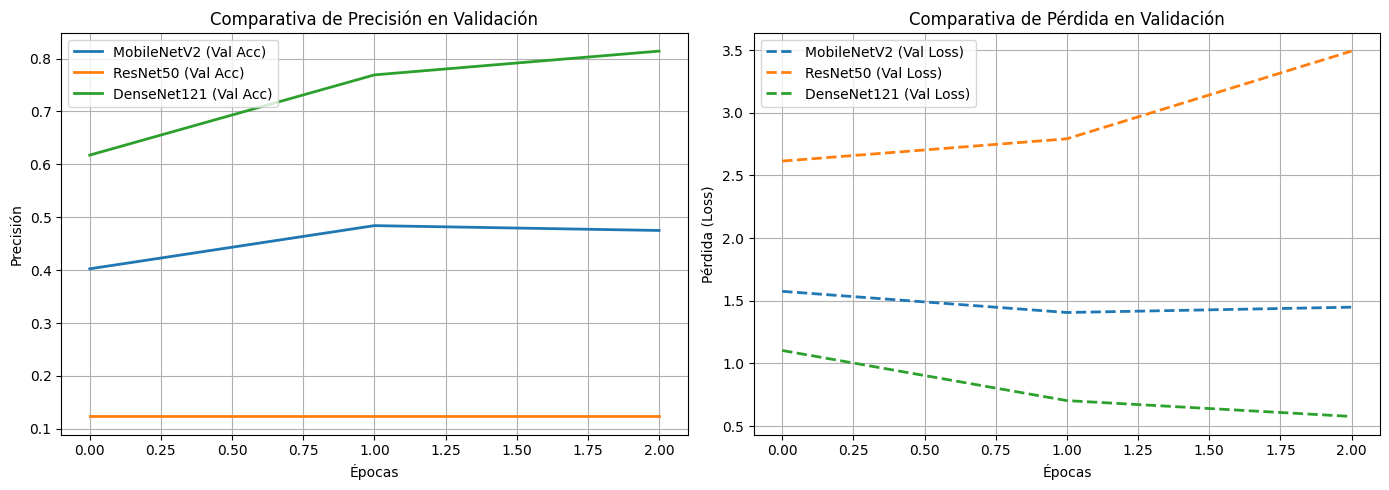

In [ ]:
plt.figure(figsize=(14, 5))

# Gráfica de Precisión
plt.subplot(1, 2, 1)
for nombre, res in resultados_modelos.items():
  plt.plot(
      res["history"].history["val_accuracy"],
      label=f"{nombre} (Val Acc)",
      linewidth=2,
  )
plt.title("Comparativa de Precisión en Validación")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.grid(True)
plt.legend()

# Gráfica de Pérdida
plt.subplot(1, 2, 2)
for nombre, res in resultados_modelos.items():
  plt.plot(
      res["history"].history["val_loss"],
      label=f"{nombre} (Val Loss)",
      linestyle="--",
      linewidth=2,
  )
plt.title("Comparativa de Pérdida en Validación")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (Loss)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

## Análisis de Errores: Matrices de Confusión por Modelo

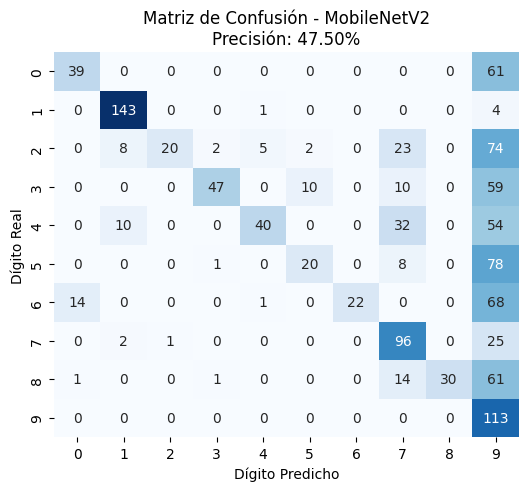

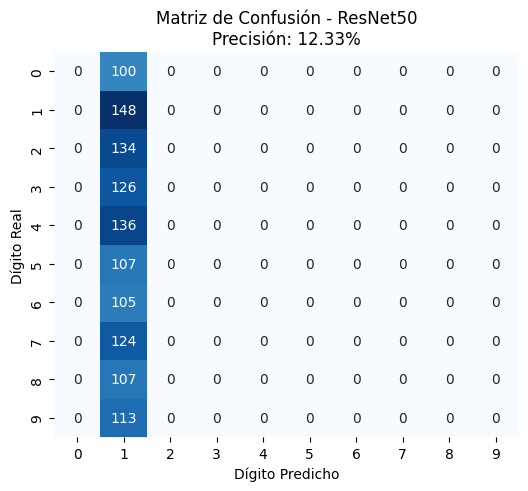

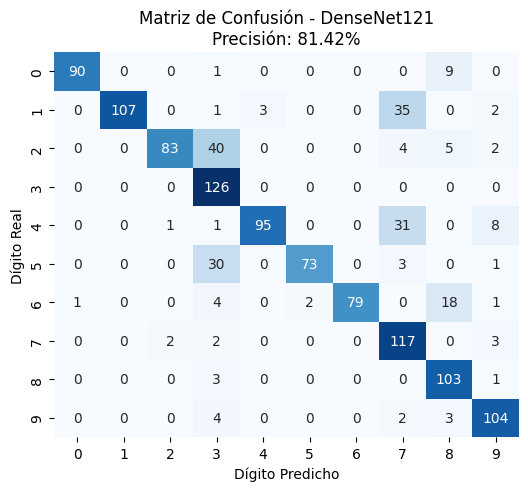

In [ ]:
for nombre, res in resultados_modelos.items():
  cm = confusion_matrix(y_test, res["y_pred"])
  plt.figure(figsize=(6, 5))
  sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
  plt.title(
      f"Matriz de Confusión - {nombre}\nPrecisión: {res['accuracy']*100:.2f}%"
  )
  plt.xlabel("Dígito Predicho")
  plt.ylabel("Dígito Real")
  plt.show()

## Selección del Mejor Modelo y Guardado en Disco


* **Rendimiento vs. Coste (*Trade-off*):** A través de las métricas temporales y de precisión observadas en la tabla resumen, se comprueba que modelos profundos alcanzan mejores tasas de acierto, requiriendo sin embargo un mayor coste computacional en comparación con opciones ligeras.
* **Análisis de Confusiones:** Las matrices de confusión revelan que los errores de clasificación se concentran principalmente en pares de dígitos visualmente similares (por ejemplo, el `4` con el `9`, o el `3` con el `5` o el `8`), debido a la superposición en sus curvas y trazos geométricos.

In [ ]:
# Criterio de selección basado en la mayor precisión
mejor_nombre = max(
    resultados_modelos, key=lambda k: resultados_modelos[k]["accuracy"]
)
mejor_info = resultados_modelos[mejor_nombre]

print("\n"  + "=" * 50 )
print(f" EL MODELO SELECCIONADO COMO EL MEJOR ES: {mejor_nombre}")
print("=" * 52)
print(f"• Precisión en Test: {mejor_info['accuracy']*100:.2f}%")
print(f"• Pérdida (Loss):     {mejor_info['loss']:.4f}")
print(f"• Tiempo de entrenamiento: {mejor_info['time']:.2f} segundos")
print("=" * 52)

# Guardar el modelo en disco
nombre_archivo_disco = f"mejor_modelo_{mejor_nombre.lower()}_mnist.keras"
mejor_info["model"].save(nombre_archivo_disco)
print(
    f" El modelo ganador ha sido guardado exitosamente en disco como:"
    f" '{nombre_archivo_disco}'"
)


 EL MODELO SELECCIONADO COMO EL MEJOR ES: DenseNet121
• Precisión en Test: 81.42%
• Pérdida (Loss):     0.5769
• Tiempo de entrenamiento: 439.40 segundos
 El modelo ganador ha sido guardado exitosamente en disco como: 'mejor_modelo_densenet121_mnist.keras'


## Conclusión
A lo largo de esta práctica, se ha evaluado el rendimiento de tres arquitecturas de redes neuronales convolucionales pre-entrenadas (**MobileNetV2**, **ResNet50** y **DenseNet121**) aplicadas al conjunto de datos **MNIST** mediante la técnica de *Transfer Learning*.

1. **Rendimiento Predictivo:** **DenseNet121** demostró ser la arquitectura más robusta y eficaz para esta tarea, alcanzando una precisión (*accuracy*) en el conjunto de test del **81.42%** con la menor pérdida global. En contraste, **MobileNetV2** se quedó en un **47.50%** y **ResNet50** experimentó problemas severos de convergencia en este esquema particular, registrando un **12.33%**.

2. **Costo Computacional y Tiempo:** Se evidenció una relación directa entre la profundidad y densidad de conexiones de la red y el tiempo de entrenamiento requerido. **DenseNet121**, a pesar de ofrecer el mejor rendimiento, requirió un tiempo considerablemente mayor (439 segundos) en comparación con MobileNetV2 (123 segundos) y ResNet50 (152 segundos) para las 3 épocas evaluadas.

3. **Análisis de Adaptación:** La necesidad de redimensionar las imágenes de MNIST (28 x 28 a 96 x 96 píxeles y 3 canales RGB) para cumplir con los requisitos geométricos de las arquitecturas de *ImageNet* demostró que el *Transfer Learning* puede reutilizar extractores de características complejos incluso en dominios de datos completamente distintos (dígitos numéricos simples).

Dado que **DenseNet121** maximiza la reutilización de características a través de sus conexiones densas, es el mejor modelo bajo esta configuración.